# Lire une IRM au format DICOM avec Python

Ce notebook ouvre une IRM de la tête, empile ses coupes en un volume 3D, l'affiche dans les trois plans et mesure un volume en litres.

Il n'utilise que `pydicom`, `numpy` et `matplotlib`.

Les images viennent du jeu [example-dicom-structural](https://github.com/datalad/example-dicom-structural), un extrait du projet studyforrest (Hanke et al., Scientific Data, 2014). Elles sont dans le domaine public (licence PDDL). Le visage a été effacé et les champs d'identité remplacés par des valeurs fictives.

In [1]:
from pathlib import Path
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pydicom

# Des figures plus légères, pour que le notebook reste petit
plt.rcParams["figure.dpi"] = 70

## 1. Récupérer les images

La première fois, la cellule télécharge l'archive depuis GitHub (quelques dizaines de Mo) et garde les fichiers `.dcm` dans le dossier `donnees/`. Les fois suivantes elle ne télécharge rien.

In [2]:
ADRESSE = "https://github.com/datalad/example-dicom-structural/archive/refs/heads/master.zip"
DOSSIER = Path("donnees")

if not DOSSIER.exists():
    print("Téléchargement en cours")
    archive, _ = urllib.request.urlretrieve(ADRESSE)
    DOSSIER.mkdir()
    with zipfile.ZipFile(archive) as z:
        for membre in z.namelist():
            if membre.endswith(".dcm"):
                (DOSSIER / Path(membre).name).write_bytes(z.read(membre))

fichiers = sorted(DOSSIER.glob("*.dcm"))
print(len(fichiers), "fichiers DICOM")

384 fichiers DICOM


## 2. Ouvrir un fichier

Un fichier DICOM contient une image et une fiche technique, l'en-tête. Dans une IRM comme celle-ci, chaque fichier est une coupe, c'est-à-dire une tranche fine de la tête.

In [3]:
ds = pydicom.dcmread(fichiers[0])

print("Type d'examen       ", ds.Modality)
print("Séquence            ", ds.SeriesDescription)
print("Taille de l'image   ", ds.Rows, "x", ds.Columns, "pixels")
print("Taille d'un pixel   ", [round(float(v), 3) for v in ds.PixelSpacing], "mm")
print("Épaisseur de coupe  ", round(float(ds.SliceThickness), 3), "mm")

Type d'examen        MR
Séquence             anat-T1w
Taille de l'image    384 x 274 pixels
Taille d'un pixel    [0.667, 0.7] mm
Épaisseur de coupe   0.667 mm


L'image elle-même est un tableau de nombres, accessible par `pixel_array`. Plus le nombre est grand, plus le pixel est clair.

(384, 274) int16 valeurs de 0 à 147


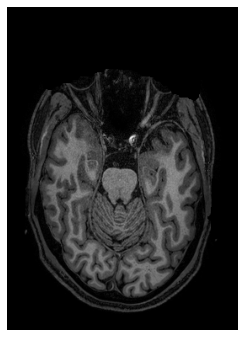

In [4]:
image = pydicom.dcmread(fichiers[200]).pixel_array
print(image.shape, image.dtype, "valeurs de", image.min(), "à", image.max())

plt.figure(figsize=(5, 6))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

## 3. Empiler les coupes en un volume

Le nom des fichiers ne garantit pas leur ordre. La bonne méthode est de lire dans chaque en-tête la position de la coupe dans l'espace, et de trier dessus.

`ImageOrientationPatient` donne la direction des lignes et des colonnes de l'image. Leur produit vectoriel donne la direction perpendiculaire à la coupe. On projette la position de chaque coupe sur cette direction et on trie.

In [5]:
coupes = [pydicom.dcmread(f) for f in fichiers]

orientation = np.array(coupes[0].ImageOrientationPatient, dtype=float)
normale = np.cross(orientation[:3], orientation[3:])

def position(coupe):
    return float(np.dot(normale, np.array(coupe.ImagePositionPatient, dtype=float)))

coupes.sort(key=position)
volume = np.stack([c.pixel_array for c in coupes])

print("Forme du volume", volume.shape, "(coupes, lignes, colonnes)")

Forme du volume (384, 384, 274) (coupes, lignes, colonnes)


Pour mesurer quoi que ce soit, il faut connaître la taille réelle d'un voxel (un pixel en 3D). Deux de ses côtés sont dans l'en-tête, le troisième est l'écart entre deux coupes voisines.

In [6]:
dz = float(np.median(np.diff([position(c) for c in coupes])))
dy, dx = (float(v) for v in coupes[0].PixelSpacing)

print(f"Un voxel mesure {dz:.2f} x {dy:.2f} x {dx:.2f} mm")
print(f"Le volume couvre {volume.shape[0] * dz / 10:.1f} x "
      f"{volume.shape[1] * dy / 10:.1f} x {volume.shape[2] * dx / 10:.1f} cm")

Un voxel mesure 0.67 x 0.67 x 0.70 mm
Le volume couvre 25.6 x 25.6 x 19.2 cm


## 4. Parcourir les coupes

Quarante coupes prises à intervalles réguliers, du cou vers le sommet du crâne.

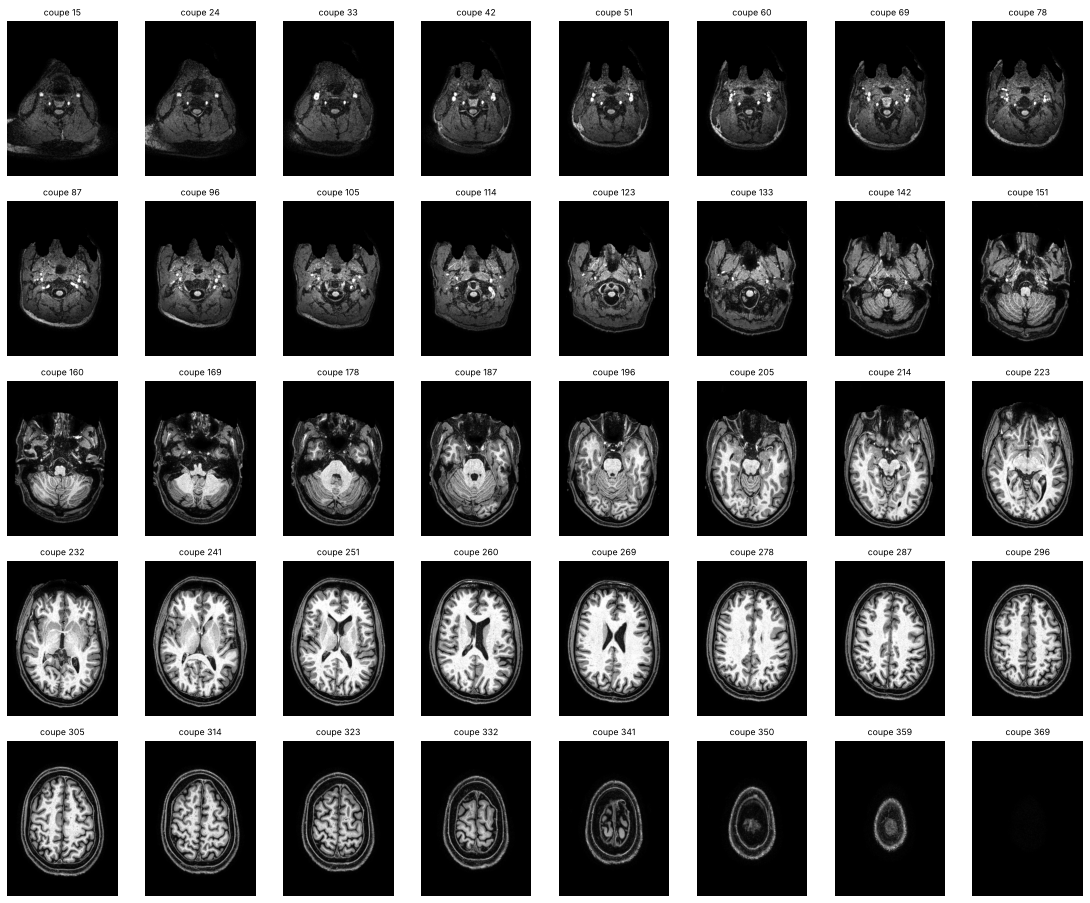

In [7]:
# Quelques voxels très brillants écraseraient le contraste, on plafonne l'affichage
haut = np.percentile(volume, 99.5)

fig, axes = plt.subplots(5, 8, figsize=(16, 13))
numeros = np.linspace(15, volume.shape[0] - 15, axes.size).astype(int)

for ax, k in zip(axes.flat, numeros):
    ax.imshow(volume[k], cmap="gray", vmax=haut)
    ax.set_title(f"coupe {k}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()